In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Membaca Dataset
df = pd.read_csv("Mall_Customers.csv")
print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [3]:
# Fitur yang Digunakan
df = df[['Annual Income (k$)', 'Spending Score (1-100)']]
print(df)

     Annual Income (k$)  Spending Score (1-100)
0                    15                      39
1                    15                      81
2                    16                       6
3                    16                      77
4                    17                      40
..                  ...                     ...
195                 120                      79
196                 126                      28
197                 126                      74
198                 137                      18
199                 137                      83

[200 rows x 2 columns]


<function matplotlib.pyplot.show(close=None, block=None)>

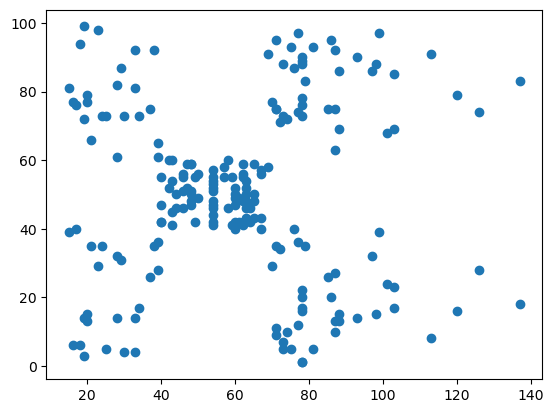

In [4]:
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

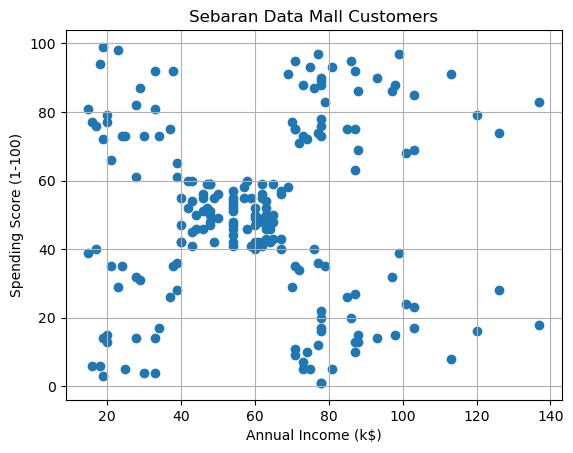

In [5]:
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Sebaran Data Mall Customers')
plt.grid(True)
plt.show

In [6]:
x_array = np.array(df)

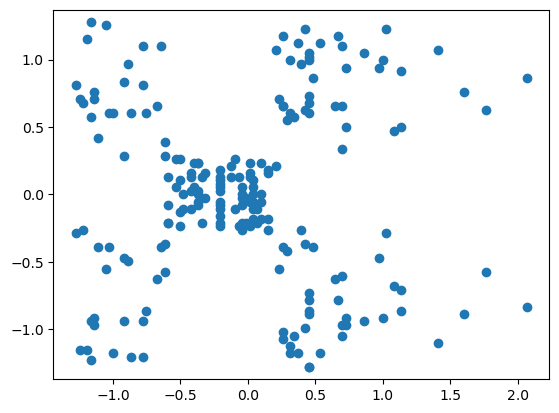

In [7]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
x_scaled = scaler.fit_transform(x_array)

plt.scatter(x_scaled[:, 0], x_scaled[:, 1])
plt.axis('equal')
plt.show()

C:\Users\Gangsar\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Gangsar\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Gangsar\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Gangsar\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory le

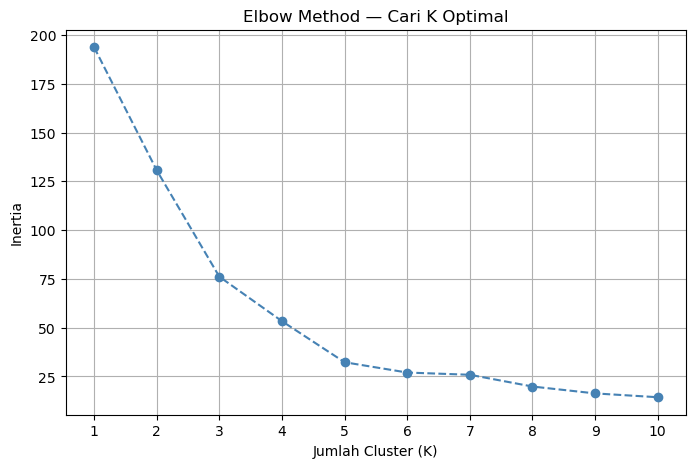

In [8]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


inertia = []
k_range = range(1, 11)  

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=0)
    kmeans_temp.fit(x_scaled)
    inertia.append(kmeans_temp.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='steelblue')
plt.title('Elbow Method — Cari K Optimal')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(k_range)
plt.grid(True)
plt.show()

In [9]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 5, random_state=0)
kmeans.fit(x_scaled)

C:\Users\Gangsar\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=5, random_state=0)

In [10]:
kmeans.cluster_centers_

array([[-0.16996449, -0.01258775],
       [ 0.68598525,  0.83995308],
       [-0.98007472,  0.76767677],
       [ 0.73150685, -0.85975724],
       [-0.96426444, -0.76044331]])

<function matplotlib.pyplot.show(close=None, block=None)>

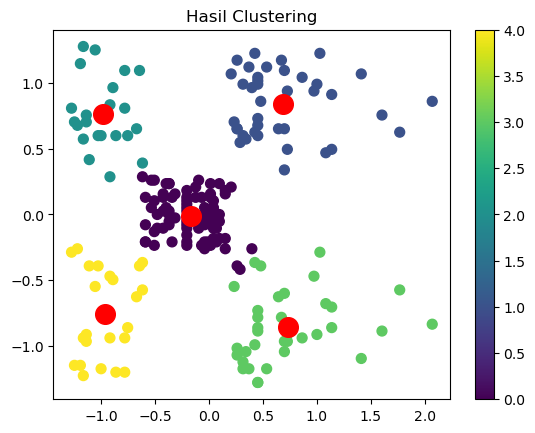

In [11]:
output = plt.scatter(x_scaled[:,0],
                     x_scaled[:,1],
                     s= 50,
                     c = kmeans.labels_)
centers = kmeans.cluster_centers_

plt.scatter(centers[:,0], centers[:,1], c = 'red', s=200)
plt.title("Hasil Clustering")
plt.colorbar(output)
plt.show

In [12]:
from sklearn.metrics import davies_bouldin_score
labels = kmeans.labels_
davies_bouldin_score(x_scaled, labels)

np.float64(0.5733769537534883)